<h1 style="color:red" align = center>INTRODUCTION TO MACHINE LEARNING</h1>
<h1 style="color:red" align = center> ChurnGuard GROUP PROJECT </h1>
<h2 style="color:red"align = center>Instructor: Dr. Khaled Mohamad</h2>

### TEAM ROLES:

<table style="text-align:left">
<tr>
    <th>Member</th>
    <th>Student ID</th>
    <th>Role</th>
</tr>
<tr>
    <td>Tairuly Nursat</td>
    <td>24B031110</td>
    <td>EDA Lead</td>
</tr>
<tr>
    <td>Gaukarbek Akmaral</td>
    <td>24B031725</td>
    <td>Modelling Lead</td>
</tr>
<tr>
    <td>Bayandiev Alibek</td>
    <td>24B031696</td>
    <td>Report & Presentation Lead</td>
</tr>
</table>

In [1]:
# Imports of dataset and needed libraries. 
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

import warnings 
warnings.filterwarnings("ignore")

df = pd.read_csv("Customer_Churn.csv") 

<h2 style="color:blue">1. Dataset Overview.</h2>

We used the **Iranian Churn** dataset from the UCI Machine Learning Repository:
`https://archive.ics.uci.edu/dataset/563/iranian+churn+dat`.
<br>The dataset contains customer information from an Iranian telecommunications company. It has **3150 rows** and **14 columns**: 13 features and one target column(`Churn`).

**Problem type:** classification.

**Target variable:** `Churn` - indicates whether a customer left the company `(Churn = 1)` or stayed `(Churn = 0)`.



In [2]:
display(df.shape)
display(df.head())

(3150, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


<h3 style="color:blue">1.1 Data Types Overview</h2>

<h4 style="color:orange">Our data consists of numerical dtypes.</h4>


<h3 style="color:blue">Data Types and Column Classification</h3>

We can divide the columns in our dataset into three types:

<h4 style="color:brown">1. Binary (True/False, represented by integers)</h4>

- **1/0 notation:**
  - `Complains` (had complaints / did not have complaints)
  - `Churn` (left / stayed)

- **2/1 notation:**
  - `Tariff Plan` (contractual / pay-as-you-go)
  - `Status` (active / non-active)

<h4 style="color:brown">2. Common Integers</h4>

- **With limits:**
  - `Charge Amount` (min: 0, max: 10)
  - `Age Group` (min: 1, max: 5)

- **Without limits:**
  - `Age`
  - `Call Failures`
  - `Subscription Length` (months)
  - `Seconds of Use`
  - `Frequency of Use` (total number of calls)
  - `Frequency of SMS`
  - `Distinct Called Numbers`

<h4 style="color:brown">3. Float</h4>

- `Customer Value` (the calculated value of a customer)

---

In summary, we can divide our dataframe columns into three types: **Binary, Integer, and Float**. As you can see above, this is a more detailed explanation of columns that are not easy to understand or have specific limitations.

The first problem we noticed with the dataframe was its lack of consistency. For example, calling `Call Failure` may cause an error because the original dataset contains two spaces in its column name, while `Tariff Plan` contains only one. We also noticed an inconsistency in binary notation: some columns use the 1/0 notation, while others use 2/1 notation. There is a certain logic behind this (1/0 represents T/F, while 2/1 is used for other categories), but overall, it is confusing. These inconsistencies can cause our group to waste time or make mistakes in the program logic.

<p style="color:#F59E0B"><b>We should try to standardize everything.</b></p>

Therefore, we will fix these problems by modifying our data during the data-cleaning process.

---

We can observe that `df.info()` and `df.describe()` confirm our statements about the division of numerical data types.



We can clearly see that the minimum and maximum values for Common Integers with limits match the values mentioned above. We can also observe from the minimum and maximum values that we really have Binary-type columns.

Moreover, we can see that the mean (average) is higher than the median (50%) for `Charge Amount`, `Seconds of Use`, and other columns (except `Subscription Length` and `Age Group`). This means that most of our columns are likely to be positively skewed.



We can also see that there are **no missing values**.

---

<h4 style="color:blue">Our Main Prediction</h4>

Our main prediction is that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.

<h4 style="color:brown">Detailed Analysis of the Target Variable (<code>Churn</code>) is provided in Section 3.</h4>


In [3]:
display(df.info())
display(df.describe()) 
display(df.dtypes)
display(df.isnull().sum())

print("Complains unique values:", df["Complains"].unique())
print("Churn unique values:", df["Churn"].unique())
print("Tariff Plan unique values:", df["Tariff Plan"].unique())
print("Status unique values:", df["Status"].unique())
print("Charge  Amount unique values:", np.sort(df["Charge  Amount"].unique()))
print("Age Group unique values:", np.sort(df["Age Group"].unique()))

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

None

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Complains unique values: [0 1]
Churn unique values: [0 1]
Tariff Plan unique values: [1 2]
Status unique values: [1 2]
Charge  Amount unique values: [ 0  1  2  3  4  5  6  7  8  9 10]
Age Group unique values: [1 2 3 4 5]



<h4 style="color:blue">1.2 Target variable analysis</h4>

Our target variable is <code>Churn</code>, which indicates whether a customer left the service or stayed.

- <code>0</code> — Customer stayed.
- <code>1</code> — Customer left.

As we can see, the dataset contains **3,150 customers**:
- **2,655 customers (84.29%)** stayed.
- **495 customers (15.71%)** left.

In [4]:
display(df["Churn"].value_counts())

Churn
0    2655
1     495
Name: count, dtype: int64

<h2 style="color:blue">1.3 Data cleaning</h3>

/////////////ORANGE We will divide our dataframe into 3 parts:

df, original dataframe without any changes. It will be used to analyze dataframe before cleaning.
df_analyze, dataframe cleaned from duplicates. It will be used to analyze dataframe after cleaning.
df_clean, dataframe cleaned from duplicates and solved problem of skewness. It will be used to train model. We need three dataframes, because all of them represent diffrent aspect of dataframe and have diffrent purposes/////////////////

<h3 style="color:blue">1.3.1 Missing-values and Duplicates check</h3>

In [5]:
display(df.isnull().sum())
display(df.duplicated().sum())
df[df.duplicated()]

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

np.int64(300)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
518,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
628,0,0,35,0,0,0,0,0,2,1,2,25,0.00,1
718,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
728,0,0,36,0,0,0,0,0,3,1,2,30,0.00,1
901,0,0,38,0,0,0,0,0,2,1,2,25,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0


<h3 style="color:blue">1.3.2 Duplicates cleaning.</h3>

In [6]:
df_analyze = df.copy()


df_analyze.drop_duplicates(inplace=True)
df_analyze.rename(columns={'Call  Failure': 'Call Failure', 'Subscription  Length': 'Subscription Length', 'Charge  Amount': 'Charge Amount'}, inplace=True)
df_analyze["Tariff Plan"] = df_analyze["Tariff Plan"] - 1
df_analyze["Status"] = df_analyze["Status"] - 1


display(df_analyze.shape)
df_analyze.head()

(2850, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,0,0,30,197.640,0
1,0,0,39,0,318,5,7,4,2,0,1,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,0,0,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,0,0,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,0,0,15,145.805,0


<h3 style="color:blue">1.3.3 Skewness check</h3>

?//////////////////
We can devide Skewness into:
Skewness < 0: Negative(Left skew)
Skewness > 0: Positive(Right skew)

Skewness represent symmetricity of our data.
Skewness = 0: symmetric 
0 < Skewness < 0.5 or 0 > Skewness > -0.5: approximately symmetric
0.5 < Skewness < 1 or -0.5 > Skewness > -1: moderately symmetric
Skewness > 1 or Skewness < -1: asymmetric

We should try to avoid asymmetry in our data. Most of them have skewness > 1. If we train our model on Linear Regression or KNN, it will give us inaccurate results, because these algorithms are too simple to handle it. For example, we have a dataframe about cats. If we want to use a KNN model, and in the dataframe the average customers have 0 or 1 cats, but some customers have 10 cats, then, because KNN picks the nearest neighbors, its predictions will sometimes jump because of the customers with 10 cats.


We will solve this problem by applying the following transformations to all columns except binary types (because they consist of 0/1) and Age Group (because it has acceptable skewness):
- ** 0.5 for positive skew
- ** 2 for negative skew

///////////////////////

In [7]:
df_clean = df_analyze.copy()
df_analyze.skew()

Call Failure               1.067233
Complains                  3.080435
Subscription Length       -1.252843
Charge Amount              2.533804
Seconds of Use             1.314737
Frequency of use           1.145862
Frequency of SMS           1.971020
Distinct Called Numbers    1.039277
Age Group                  0.453043
Tariff Plan                3.089147
Status                     1.218203
Age                        1.223952
Customer Value             1.422214
Churn                      1.891937
dtype: float64

<h3 style="color:blue">1.3.4 Skewness problem solved</h3>

In [8]:
positive_skew = ["Charge Amount", "Seconds of Use", "Frequency of use", "Distinct Called Numbers", "Age", "Customer Value", "Call Failure", "Frequency of SMS"]
negative_skew = "Subscription Length"

for col in positive_skew:
    df_clean[col] = df_clean[col] ** 0.5
df_clean[negative_skew] = df_clean[negative_skew] ** 2
df_clean.skew()

Call Failure              -0.129865
Complains                  3.080435
Subscription Length       -0.578399
Charge Amount              0.823158
Seconds of Use             0.372402
Frequency of use           0.101230
Frequency of SMS           0.987236
Distinct Called Numbers   -0.193075
Age Group                  0.453043
Tariff Plan                3.089147
Status                     1.218203
Age                        0.829932
Customer Value             0.646432
Churn                      1.891937
dtype: float64

The skewness problem is now solved, so we can train our models.

<h3 style="color:blue">1.3.5 Ghost Customers Problem</h3>

In [9]:
df_ghost = df_analyze[df_analyze["Customer Value"] == 0]
display(df_ghost["Churn"].value_counts())

Churn
1    44
0    41
Name: count, dtype: int64



While investigating the values in our dataframe, we found a problem: some customers have **0 values** for `Frequency of Use`, `Frequency of SMS`, and `Customer Value`.

We then checked the `Churn` values for these rows to determine whether they should be removed. The results showed that **44 customers had churned** (`Churn = 1`), while **41 customers had stayed** (`Churn = 0`).

<p style="color:orange"><b>Therefore, we decided not to remove these rows and keep them in our dataset.</b></p>


<h3 style="color:blue">1.3.6 Class Distribution</h3>

'Before:'

Churn
0    2655
1     495
Name: count, dtype: int64

'After:'

Churn
0    2404
1     446
Name: count, dtype: int64

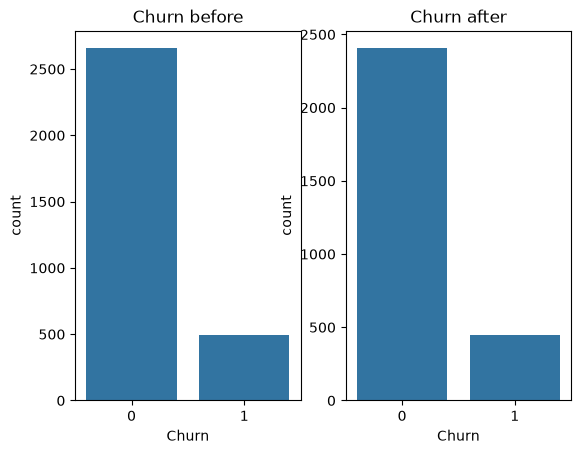

In [10]:
plt.subplot(1,2,1)
sns.countplot(x = "Churn", data = df)
plt.title("Churn before")
plt.subplot(1,2,2)
sns.countplot(x = "Churn", data = df_analyze)
plt.title("Churn after")

display("Before:", df["Churn"].value_counts())
display("After:", df_analyze["Churn"].value_counts())




We can clearly see that the class distributions before and after cleaning are practically identical. The main difference is that the cleaned dataset contains **300 fewer rows**.

Before cleaning:
- `Churn = 0`: 2,655 customers
- `Churn = 1`: 495 customers

After cleaning:
- `Churn = 0`: 2,404 customers
- `Churn = 1`: 446 customers

Overall, the percentages have barely changed. The proportion of customers who churned was approximately **15.71% before cleaning** and **15.65% after cleaning**. Therefore, the difference is only about **0.06 percentage points**, which means that the class distribution remained almost unchanged after data cleaning.

<p style="color:orange"><b>Important:</b> Our dataset has an imbalanced target variable because the number of customers who stayed (2,404, about 84.4%) is significantly higher than the number of customers who left (446, about 15.6%).</p>

This class imbalance may affect our machine learning model. Therefore, in Week 3, we should consider using a stratified train/test split and evaluating the model with metrics such as **F1-score**, rather than relying only on accuracy.


<h3 style="color:blue">1.3.7 Overall Conclusion</h3>




We checked the dataframe for:

- *Missing values:* **0 missing values**

There are no missing values, so there is no reason to delete any rows for this reason.

<p style="color:orange"><b>No imputation strategy is required because there are no missing values. Therefore, there are no rows that need to be modified through imputation.</b></p>

- *Duplicates:* **300 duplicate rows**

We need to prevent potential data leakage and problems caused by duplicate rows. We will solve this problem by deleting duplicates.

After cleaning our data, the dataset now has **2,850 rows instead of 3,150**.

<table>
<tr>
<th></th>
<th>Before</th>
<th>After</th>
</tr>
<tr>
<td>Rows</td>
<td>3,150 rows</td>
<td>2,850 rows</td>
</tr>
<tr>
<td>Percentage of original data</td>
<td>100%</td>
<td>90.5%</td>
</tr>
<tr>
<td>Churned customers</td>
<td>495</td>
<td>446</td>
</tr>
<tr>
<td>Churn rate</td>
<td>15.7%</td>
<td>15.6%</td>
</tr>
</table>

Also, we thought there could be a **hidden problem with Ghost Customers** (customers who have 0 values in `Frequency of Use`, `Frequency of SMS`, and `Customer Value`), because they may lead to **data leakage**.


<h2 style="color:blue">2. Hypotesis test and Churn analysis</h2>




We hypothesized that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.

It is difficult to visualize `Call Failure`, so we created a new column called `High Failure`. This means that the dataset now has **15 columns instead of 14**.



In [11]:
df_analyze["Churn"].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

<h3 style="color:blue">2.1 Churn X Complains connection</h3>

<Axes: xlabel='Complains', ylabel='Churn'>

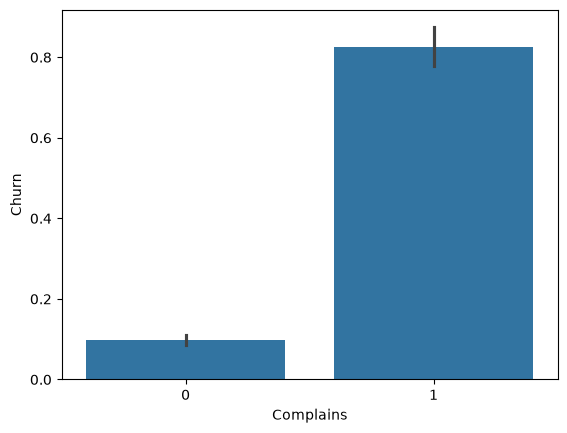

In [12]:
sns.barplot(data=df_analyze, x='Complains', y='Churn')


<h3 style="color:blue">2.1 Churn vs. Complains Connection</h3>



Our bar plot visualization of `Complains` against `Churn` shows that **complaints have a strong relationship with customer churn**.

The difference between customers who filed complaints and those who did not is significant — approximately **0.7** in the average `Churn` value. This difference is clearly visible in the binary `Churn` variable.
 
<p style="color:orange"><b>Customers who filed complaints are much more likely to churn than customers who did not.</b></p>


<h3 style="color:blue">2.2 Churn X High Failure connection</h3>

<Axes: xlabel='High Failure', ylabel='Churn'>

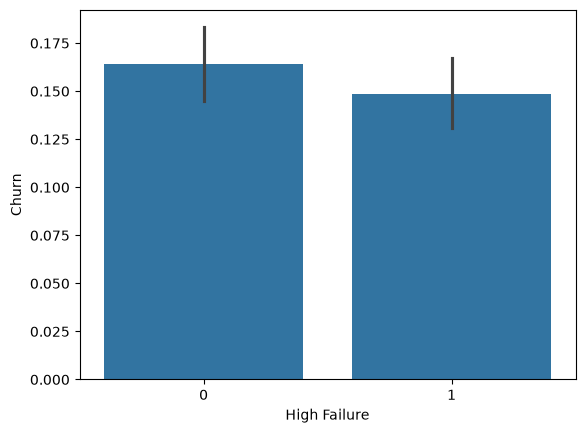

In [13]:
df_analyze["High Failure"] = (df_analyze["Call Failure"] > (df_analyze["Call Failure"].median())).astype("int")
df_clean["High Failure"] = df_analyze["High Failure"]
sns.barplot(data=df_analyze, x='High Failure', y='Churn')


<h3 style="color:blue">2.2 Churn vs. High Failure Connection</h3>



Our bar plot visualization of `High Failure` against `Churn` shows that **high call failure does not appear to have a strong relationship with customer churn**.

The difference between the average `Churn` values for customers with low and high call failure is approximately **0.013**. This difference is relatively small.

<p style="color:orange"><b>This result may indicate a problem with our initial hypothesis, as high call failure does not seem to be a strong predictor of customer churn in our dataset.</b></p>


<h3 style="color:blue">2.3 Crosstable with both Complains and High Failure and its Analysis</h3>




We created a crosstab using both `Complains` and `High Failure`, and we can clearly observe the following:

- Customers who **did not experience many call failures** and **did not have any complaints** have a churn rate of only **12%**.
- Customers who **did not experience many call failures** but **had complaints** have a churn rate of **98%**.
- Customers who **experienced many call failures** but **did not have any complaints** have a churn rate of **9%**.
- Customers who **experienced many call failures** and **had complaints** have a churn rate of **78%**.

<p style="color:orange"><b>The results show that complaints are a much stronger indicator of churn than high call failure alone. Customers who filed complaints had a high churn rate regardless of their call failure level.</b></p>


In [14]:
crossCompAFail = pd.crosstab(df_analyze["Churn"], [df_analyze["High Failure"],df_analyze["Complains"]] , margins = True)
crossCompAFail

High Failure     0         1        All
Complains        0   1     0    1      
Churn                                  
0             1216   3  1148   37  2404
1              160  79    96  111   446
All           1376  82  1244  148  2850

<h3 style="color:blue">2.4 Conclusion for 1st Part</h3>

Our hypothesis is only partly true:
- **True:** We can observe that customers who *had any complaints* have a **higher percentage of Churn**.
- **False:** We can observe that even if customers *experienced many failures*, they still have a **lower percentage of Churn**.

<h3 style="color:blue">2.5 Why our Hypothesis doesn't work properly</h3>

<h3 style="color:orange">There is a lot of possible reasons, here they are:</h3>

- <h4 style="color:brown">There is a possibility that this is because we concentrated only on the number of <code>Call  Failure</code>, not on the percentage of <code>Call  Failure</code> among <code>Frequency of use</code>.</h4>

The percetage for High Failure: 19.9 %
The percetage for Low Failure:  9.19 %
The percetage for df_analyze:      14.6 %


Text(0, 0.5, 'Number of customers')

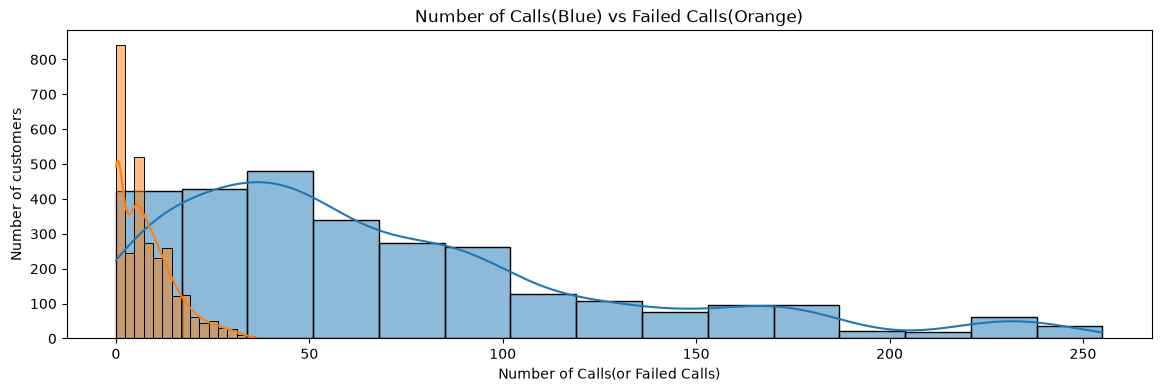

In [15]:
df_High_Failure = df_analyze[(df_analyze["High Failure"] == 1)]
df_Low_Failure = df_analyze[(df_analyze["High Failure"] == 0)]

df_High_Failure_no0Calls = df_High_Failure[df_High_Failure["Frequency of use"] != 0]
df_Low_Failure_no0Calls = df_Low_Failure[df_Low_Failure["Frequency of use"] != 0]
df_no0Calls = df_analyze[df_analyze["Frequency of use"] != 0]
avg_FailsperCalls_HighF = (df_High_Failure_no0Calls["Call Failure"]/df_High_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_LowF = (df_Low_Failure_no0Calls["Call Failure"]/df_Low_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_AllDf =(df_no0Calls["Call Failure"]/(df_no0Calls["Frequency of use"])).mean()

print("The percetage for High Failure:", (avg_FailsperCalls_HighF*100).round(1),"%")
print("The percetage for Low Failure: ", (avg_FailsperCalls_LowF*100).round(2),"%")
print("The percetage for df_analyze:     ", (avg_FailsperCalls_AllDf*100).round(1),"%")

plt.figure(figsize=(14,4))
#Age Distribution
plt.subplot(1,1,1)
sns.histplot(df_analyze["Frequency of use"], kde = True, bins = 15)
sns.histplot(df_analyze["Call Failure"], kde = True, bins = 15)
plt.title("Number of Calls(Blue) vs Failed Calls(Orange)") 
plt.xlabel("Number of Calls(or Failed Calls)")
plt.ylabel("Number of customers")


<p style="color:#A16207"><b>Histogram Breakdown</b></p>

These histograms show us the number of calls (blue) and failed calls (orange) per customer. We can observe the following trends:

- **For Calls:**
  - The maximum number of calls is slightly above 250.
  - Most customers make fewer than 100 calls.
  - The number of calls per customer initially increases slightly and then declines.
  - The maximum number of customers within a single bin is approximately 500.

- **For Failed Calls:**
  - The maximum number of failed calls is slightly below 40.
  - Most customers have fewer than 12 failed calls.
  - The number of failed calls per customer decreases as the number of failed calls increases.
  - The maximum number of customers within a single bin is approximately 500.





<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers with `High Failure` also have a high percentage of failed calls (**19.6%**), while customers with `Low Failure` (`High Failure == 0`) have a much lower percentage of failed calls (**3.65%**).


---
////ORANGE Let's visualize all relationships in dataframe with heatmap to view other possiblle reasons/////////

<Axes: >

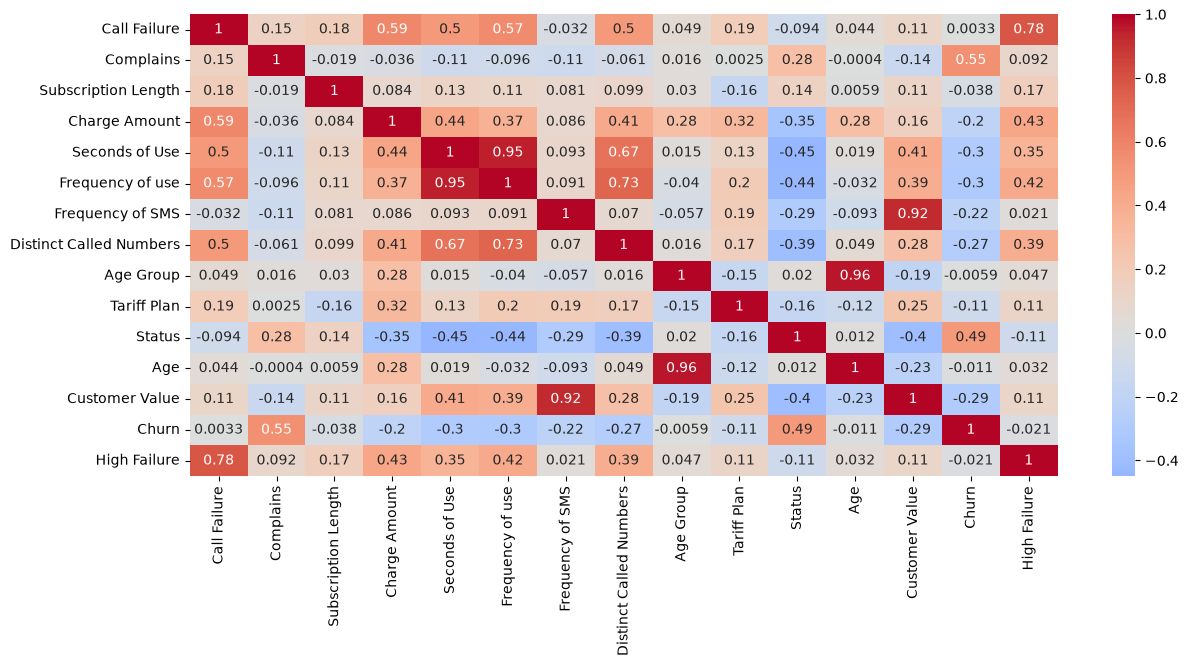

In [16]:
plt.figure(figsize=(14,6))
plt.subplot(1,1,1)
numeric_cols = df_analyze.columns
sns.heatmap(df_analyze[numeric_cols].corr(), annot=True, cmap = 'coolwarm', center = 0)

////////////As you can observe, this heatmap represents relationship of every columns with each other. It's very reliable, we can see that Age and Age Group have high value of 0.96. We can say that most of variable have some sort of relationship between them
ТУТ НЕ ДОДЕЛАНО Я САм 
<br>But let's return to our theme. We could use this heatmap, but we won't use it to understand real life possible connections between them./////////////

---


<ul>
<li style="color:#B91C1C">Another possibility is that these customers are more loyal because their <code>Subscription Length</code> is higher, making it harder for them to switch providers.</li>
</ul>


In [17]:
print("Avg Subscription Length for High  Failure:", (df_High_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for Low  Failure: ", (df_Low_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for df_analyze:     ", (df_analyze["Subscription Length"]).mean().round(1),"months")

Avg Subscription Length for High  Failure: 33.9 months
Avg Subscription Length for Low  Failure:  31.0 months
Avg Subscription Length for df_analyze:      32.5 months



<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers have very similar `Subscription Length` values, with a difference of only **3.3 months** between the two groups.


---


<ul>
<li style="color:#B91C1C">Another possibility is that these customers are older (where <code>Age Group</code> ranges from 1 (youngest) to 5 (oldest)) and may not know how to switch providers, so they decide to stay.</li>
</ul>


In [18]:
print("Avg Age Group for High Failure:", (df_High_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for Low Failure:", (df_Low_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for whole df_analyze:", (df_analyze["Age Group"]).mean().round(1))

Avg Age Group for High Failure: 2.9
Avg Age Group for Low Failure: 2.8
Avg Age Group for whole df_analyze: 2.8



<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers have very similar `Age Group` values, with a difference of only **0.1** between the two groups.


---


<h4 style="color:blue">Visualizing the Remaining Possibilities with a Heatmap</h4>


<Axes: >

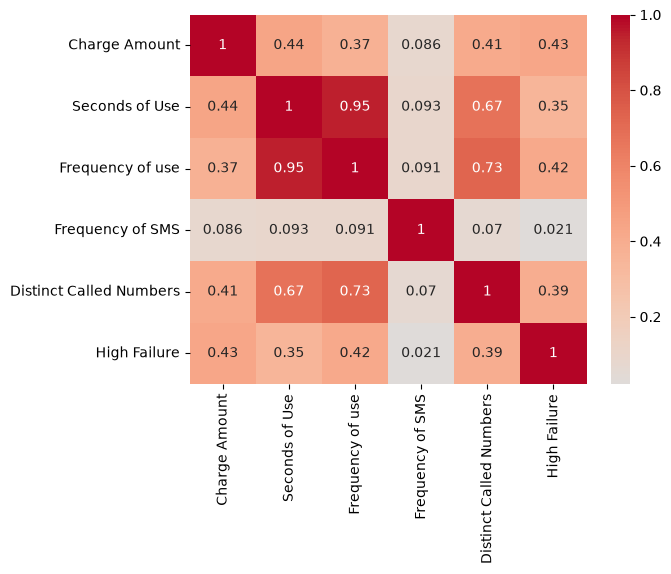

In [19]:
df_heat = df_analyze.copy()
df_heat.drop(columns=["Call Failure", "Complains", "Subscription Length", "Age Group", "Tariff Plan", "Status", "Age", "Customer Value", "Churn" ], inplace=True,             errors = "ignore")
numeric_cols = df_heat.columns
sns.heatmap(df_heat[numeric_cols].corr(), annot=True, cmap = 'coolwarm', center = 0)


<h4 style="color:brown">Conclusion</h4>

<p style="color:#A16207"><b> This may be one of the reasons.</b></p>

We can observe that almost all the selected columns (`Charge Amount`, `Seconds of Use`, `Frequency of Use`, and `Distinct Called Numbers`), except for `Frequency of SMS`, have a relatively strong positive correlation with `High Failure` (approximately **0.30–0.36**).

This suggests that these features are related to call activity. Therefore, customers may experience high call failure while still maintaining relatively high levels of call activity.

---

In [20]:
df_analyze.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn,High Failure
0,8,0,38,0,4370,71,5,17,3,0,0,30,197.640,0,1
1,0,0,39,0,318,5,7,4,2,0,1,25,46.035,0,0
2,10,0,37,0,2453,60,359,24,3,0,0,30,1536.520,0,1
3,10,0,38,0,4198,66,1,35,1,0,0,15,240.020,0,1
4,3,0,38,0,2393,58,2,33,1,0,0,15,145.805,0,0



<hr>

<h2 style="color:blue">4. Feature Engineering</h2>



<h3 style="color:blue">4.1 Categorical Encoding</h3>

Tariff Plan and Status each have two categories. During data cleaning
**(section 1.3.2)**, we changed their original codes from **1** and **2** to **0** and **1**.

In [21]:
df_model = df_clean.copy()

encoding_counts = pd.DataFrame({"Tariff Plan": df_model["Tariff Plan"].value_counts(),"Status": df_model["Status"].value_counts()})

display(encoding_counts.sort_index())

,Tariff Plan,Status
0,2621,2166
1,229,684


<p><i><b>Tariff Plan</i></b> values: 0 = Pay-as-you-go, 1 = Contractual.<br>
<i><b>Status</i></b> values: 0 = Active, 1 = Non-active.</p>

These features have only two categories. Therefore, one binary column per feature is enough. In Logistic Regression, it helps in comparing the category coded as 1 with the reference category coded as 0.

<h3 style="color:blue">4.2 New feature: Failure Rate (row-wise, safe before the split)</h3>

In [22]:
df_analyze["Failure Rate"] =np.where(df_analyze["Frequency of use"]>0,df_analyze["Call Failure"]/ df_analyze["Frequency of use"],0)                       
df_model["Failure Rate"] = df_analyze["Failure Rate"]

print(df_analyze.groupby("Churn")["Failure Rate"].mean())
print("skew -", df_analyze["Failure Rate"].skew()," max -", df_analyze["Failure Rate"].max())

Churn
0    0.118637
1    0.258324
Name: Failure Rate, dtype: float64
skew - 4.664655426573184  max - 3.5


**Interpretation.** When comparing the mean of Failure Rates for stayers `(0.119)` to that of the leavers `(0.258)`, it was around **2.18** times higher in the leaver category. These findings align with our proposed link between churn and the failure of calls.

The feature shows high positive skewness, and the maximum recorded value is **3.5**. This means that at least one customer had more recorded call failures than recorded calls. The dataset description does not explain how failed attempts were counted, so we cannot reliably interpret this feature as the percentage of calls that failed. We use it only as the ratio of the two recorded counts. 

In cases where `no calls` have been recorded for the customer, we treat this ratio as `zero`, and the average values within each group also contain zeros.

**Conclusion.** Failure Rate may carry information that raw Call Failure does not, because it accounts for how active the customer is. During the third week, we plan to compare performance with and without this feature and see how it helps improve predictions.

In [23]:
# Это для проверки можешь удалить
df_model.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn,High Failure,Failure Rate
0,2.828427,0,1444,0.0,66.105976,8.426150,2.236068,4.123106,3,0,0,5.477226,14.058449,0,1,0.112676
1,0.000000,0,1521,0.0,17.832555,2.236068,2.645751,2.000000,2,0,1,5.000000,6.784910,0,0,0.000000
2,3.162278,0,1369,0.0,49.527770,7.745967,18.947295,4.898979,3,0,0,5.477226,39.198469,0,1,0.166667
3,3.162278,0,1444,0.0,64.791975,8.124038,1.000000,5.916080,1,0,0,3.872983,15.492579,0,1,0.151515
4,1.732051,0,1444,0.0,48.918299,7.615773,1.414214,5.744563,1,0,0,3.872983,12.074974,0,0,0.051724


In [24]:
df_analyze["High Failure"].value_counts()

High Failure
0    1458
1    1392
Name: count, dtype: int64